In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

customers = pd.read_csv("../data/clean/customers_clean.csv")

In [8]:
customers.head()
customers.shape
customers.info()
customers.describe()
customers["customer_since"]=pd.to_datetime(customers["customer_since"])

<class 'pandas.DataFrame'>
RangeIndex: 75000 entries, 0 to 74999
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   customer_id       75000 non-null  str  
 1   first_name        75000 non-null  str  
 2   last_name         75000 non-null  str  
 3   gender            75000 non-null  str  
 4   age               75000 non-null  int64
 5   marital_status    75000 non-null  str  
 6   occupation        75000 non-null  str  
 7   annual_income     75000 non-null  int64
 8   city              75000 non-null  str  
 9   state             75000 non-null  str  
 10  customer_since    75000 non-null  str  
 11  customer_segment  75000 non-null  str  
 12  customer_tenure   75000 non-null  int64
dtypes: int64(3), str(10)
memory usage: 7.4 MB


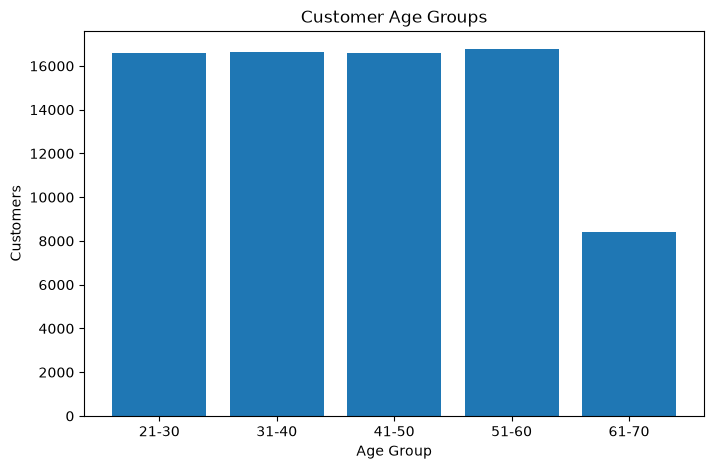

In [9]:
customers["age_group"] = pd.cut(
    customers["age"],
    bins=[20,30,40,50,60,70],
    labels=[
        "21-30",
        "31-40",
        "41-50",
        "51-60",
        "61-70"
    ]
)

age_group = customers["age_group"].value_counts().sort_index()

plt.figure(figsize=(8,5))
plt.bar(age_group.index.astype(str), age_group.values)

plt.title("Customer Age Groups")
plt.xlabel("Age Group")
plt.ylabel("Customers")

plt.show()

Broad Core Base: The bank caters steadily to adults across all major career stages, from young professionals entering the workforce up through pre-retirees.

Retirement Transition: The decline in the 61–70 bracket likely corresponds to retirement, reduced credit need, or account consolidation into specialized pension/senior banking services

The customer base includes adults of different age groups, with most customers being middle-aged and no unusual age patterns observed.

Most customers fall between 32 and 54 years, indicating the bank primarily serves working-age individuals.

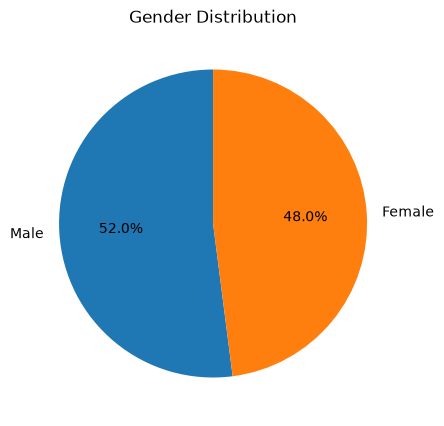

In [6]:
gender_counts = customers["gender"].value_counts()

plt.figure(figsize=(5,5))
plt.pie(
    gender_counts,
    labels=gender_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Gender Distribution")
plt.show()

count    7.500000e+04
mean     1.178258e+06
std      4.971760e+05
min      2.500000e+05
25%      7.800000e+05
50%      1.110000e+06
75%      1.480000e+06
max      3.660000e+06
Name: annual_income, dtype: float64


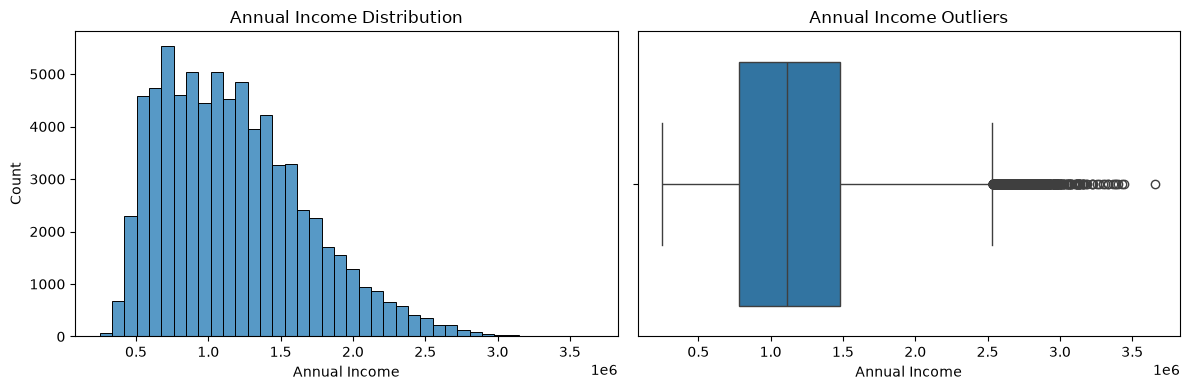

In [10]:
print(customers["annual_income"].describe())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(
    data=customers, x="annual_income", bins=40, ax=axes[0]
)
axes[0].set_title("Annual Income Distribution")
axes[0].set_xlabel("Annual Income")

sns.boxplot(data=customers, x="annual_income", ax=axes[1])
axes[1].set_title("Annual Income Outliers")
axes[1].set_xlabel("Annual Income")

plt.tight_layout()
plt.show()

Core Customer Base: Most customers earn between $500K and $1.5M annually, peaking around $750K to $1M.   
High Earners (Outliers): A small group earns significantly more, stretching up to $3.5M+.   
Main Takeaway:
Focus primary products and pricing on the $500K–$1.5M segment to drive the bulk of sales.   
Offer premium or VIP services for the $2.5M+ group to capture higher-margin revenue.

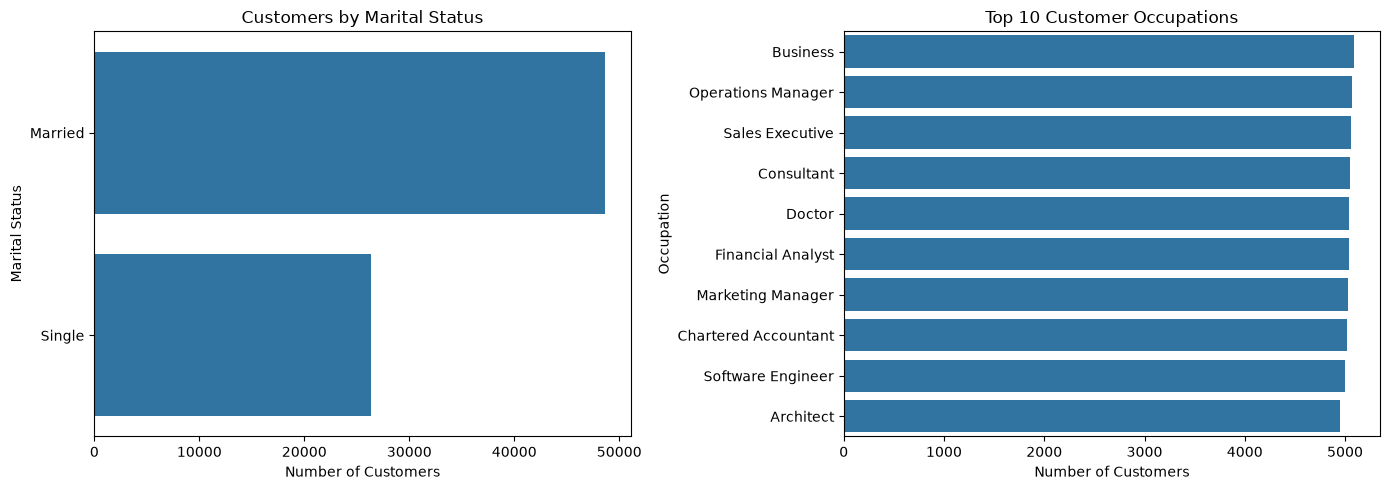

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(
    data=customers,
    y="marital_status",
    order=customers["marital_status"].value_counts().index,
    ax=axes[0]
)
axes[0].set_title("Customers by Marital Status")
axes[0].set_xlabel("Number of Customers")
axes[0].set_ylabel("Marital Status")

top_occupations = customers["occupation"].value_counts().head(10).index

sns.countplot(
    data=customers[customers["occupation"].isin(top_occupations)],
    y="occupation",
    order=top_occupations,
    ax=axes[1]
)
axes[1].set_title("Top 10 Customer Occupations")
axes[1].set_xlabel("Number of Customers")
axes[1].set_ylabel("Occupation")

plt.tight_layout()
plt.show()

Marital Status: Married customers make up nearly double the volume of single customers (~48,000 married vs. ~26,000 single).   
Occupation Breakdown: Customers are evenly spread across high-skilled, professional roles—such as Business owners, Operations Managers, Consultants, Doctors, and Engineers—each accounting for roughly 5,000 customers.   
Main Takeaway:
Tailor marketing toward families and married couples (e.g., family plans, joint accounts, or shared offers) since they represent the majority.   
Keep messaging geared toward working professionals with predictable, higher-income careers. 

,customer_count
state,
Maharashtra,17718
Gujarat,13262
Tamil Nadu,8860
Karnataka,8666
Haryana,4456
Rajasthan,4438
Telangana,4418
Uttar Pradesh,4411
Delhi,4400


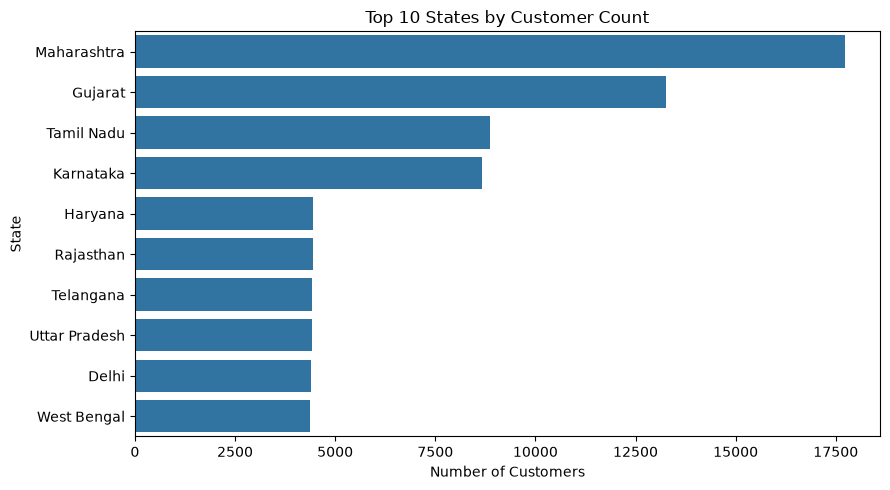

In [12]:
top_states = customers["state"].value_counts().head(10)

display(top_states.to_frame("customer_count"))

plt.figure(figsize=(9, 5))
sns.barplot(x=top_states.values, y=top_states.index)
plt.title("Top 10 States by Customer Count")
plt.xlabel("Number of Customers")
plt.ylabel("State")
plt.tight_layout()
plt.show()

Top Performing States: Maharashtra (~17,700) and Gujarat (~13,200) lead by a significant margin, making up the vast majority of the customer base. 

Secondary Markets: Tamil Nadu and Karnataka form a strong second tier with around 8,500–8,800 customers each.   

Consistent Baseline: Haryana, Rajasthan, Telangana, Uttar Pradesh, Delhi, and West Bengal show equal customer volume at around 4,400 each.
   
Main Takeaways:
Focus primary marketing budget and operations in Maharashtra and Gujarat to protect and grow core market share.   
Target the lower-volume states with growth initiatives to expand customer acquisition beyond the top regions. 

count    75000.000000
mean         6.273440
std          2.896335
min          1.000000
25%          4.000000
50%          6.000000
75%          9.000000
max         11.000000
Name: customer_tenure, dtype: float64


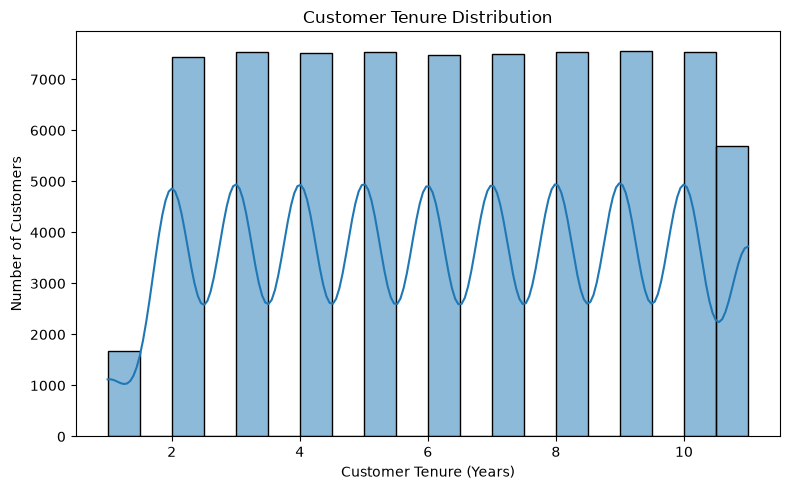

In [13]:
print(customers["customer_tenure"].describe())

plt.figure(figsize=(8, 5))
sns.histplot(data=customers, x="customer_tenure", bins=20, kde=True)
plt.title("Customer Tenure Distribution")
plt.xlabel("Customer Tenure (Years)")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

High Long-Term Retention: Customer count remains exceptionally stable at around 7,500 customers for each tenure year between Year 2 and Year 10, showing minimal churn over time.   
Low New Customer Acquisition: Year 1 tenure shows a sharp drop (~1,700 customers), indicating a recent slowdown in acquiring new customers.  

 Tenure Cap: A slight reduction occurs at Year 11 (~5,700 customers), representing the longest-standing customer cohort.   
 
 Main Takeaway:
 Strong Loyalty Foundation: The business excels at retaining existing customers once they reach Year 2.   
 Acquisition Priority: Focus heavily on marketing and sales top-of-funnel initiatives to fix the recent drop in new customer sign-ups (Year 1). 

,new_customers
acquisition_year,
2015,7384
2016,7547
2017,7523
2018,7554
2019,7569
2020,7395
2021,7548
2022,7519
2023,7559


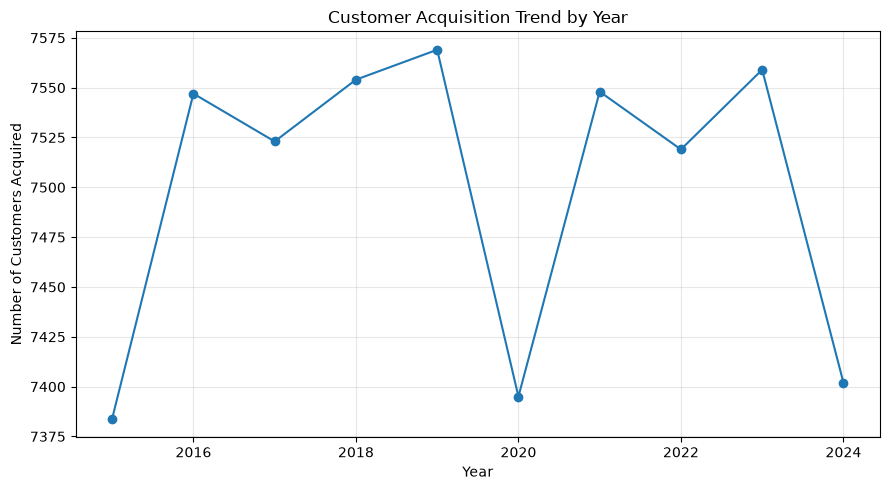

In [14]:
customers["customer_since"] = pd.to_datetime(
    customers["customer_since"], errors="coerce"
)

acquisition_trend = (
    customers.dropna(subset=["customer_since"])
    .assign(acquisition_year=lambda df: df["customer_since"].dt.year)
    .groupby("acquisition_year")["customer_id"]
    .nunique()
)

display(acquisition_trend.to_frame("new_customers"))

acquisition_trend.plot(kind="line", marker="o", figsize=(9, 5))
plt.title("Customer Acquisition Trend by Year")
plt.xlabel("Year")
plt.ylabel("Number of Customers Acquired")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Overall Stability: Customer acquisition is extremely steady over the 10-year period, hovering in a narrow range between ~7,380 and ~7,570 customers per year.   Notable Dips: Significant acquisition slowdowns occurred in 2020 (~7,395) and 2024 (~7,400).   

Peak Years: Acquisition peaked in 2019 (~7,570) and bounced back strongly in 2021 and 2023 (~7,550+).   
Main Takeaways:
Consistent Baseline Demand: The brand maintains a dependable annual intake of around ~7,500 new customers.   
Investigate Growth Barriers: Because acquisition fluctuates in a narrow band without upward compounding growth, marketing strategies need a overhaul to scale customer onboarding beyond the current ~7,500 ceiling.  